Authors:

Myles Lewis and Yuchan Jun

Dataset Background:

Optical Recognition of Handwritten Digits is a database of handwritten numbers between 0 and 9. As all of the images depict a number, it is often used for image recognition and classification problems. There are 1,797 images within this data set, and each is represented by an 8x8 pixel array (which consists of 64 values).


In [11]:
# Step 1: Import libraries
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
# Step 2: Load the dataset
# Each sample is an 8x8 handwritten digit image.
# There are 1,797 images and 10 possible digits (0-9).

digits = load_digits()

X = digits.data      # 64 pixel values for each image
y = digits.target    # The digit label: 0, 1, 2, ..., 9

print("Dataset shape:", X.shape)
print("Number of classes:", len(digits.target_names))


Dataset shape: (1797, 64)
Number of classes: 10


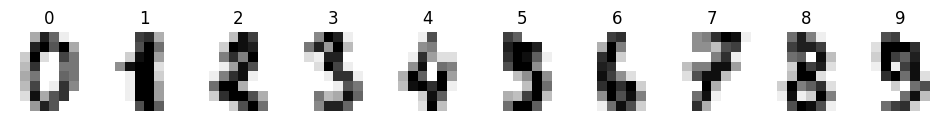

In [13]:
# Step 3: Explore the data – look at some example digits
fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(digits.target[i]); ax.axis("off")
plt.show()

In [14]:
# Step 4: Split the data
# 80% is used to train the model.
# 20% is used to test how well it works on new images.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
# Step 5: Scale the features
# KNN uses distance, so scaling helps all pixel values
# contribute fairly.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
# Step 6: Train the KNN model
# K = 5 means the model looks at the 5 closest images
# and chooses the most common digit among them.

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [17]:
# Step 7: Test the model

y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print("KNN Accuracy:", accuracy)

print(classification_report(y_test, y_pred))

KNN Accuracy: 0.9638888888888889
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       0.95      1.00      0.97        35
           3       1.00      0.97      0.99        37
           4       0.97      0.94      0.96        36
           5       0.97      0.97      0.97        37
           6       0.97      1.00      0.99        36
           7       0.92      0.97      0.95        36
           8       0.97      0.89      0.93        35
           9       0.97      0.89      0.93        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



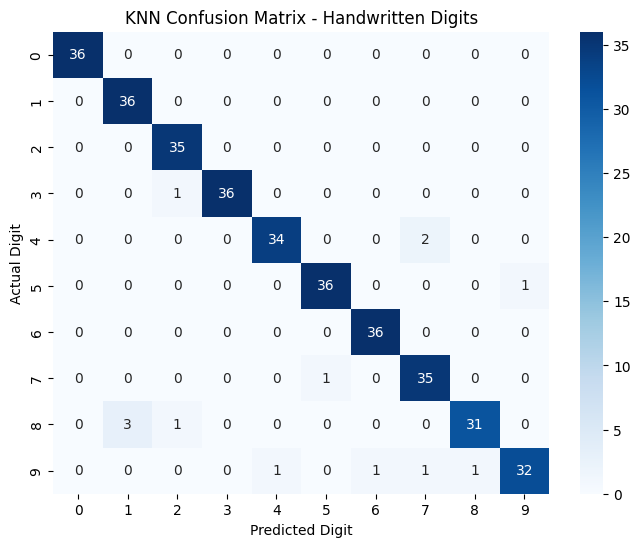

In [18]:
# Step 8: Show the confusion matrix
# The diagonal shows correct predictions.

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("KNN Confusion Matrix - Handwritten Digits")
plt.show()

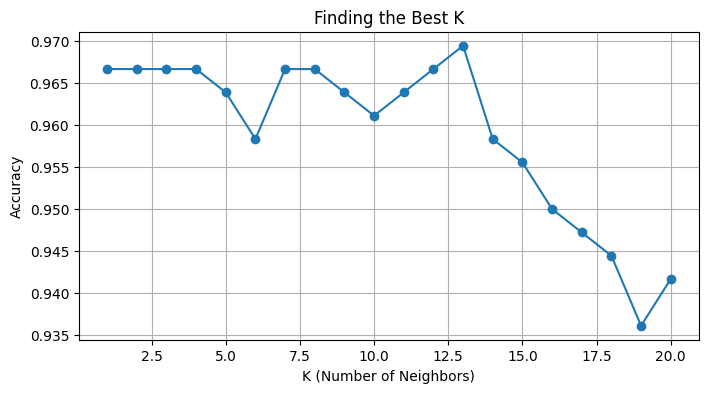

Best K: 13
Best Accuracy: 0.9694444444444444


In [19]:
# Step 9: Find the best K

k_values = range(1, 21)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, predictions))

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker="o")
plt.xlabel("K (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.title("Finding the Best K")
plt.grid()
plt.show()

best_k = list(k_values)[accuracies.index(max(accuracies))]
print("Best K:", best_k)
print("Best Accuracy:", max(accuracies))

In [20]:
# Step 10: Retrain with the best K and predict a "new" image
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

sample = X_test_scaled[0].reshape(1, -1)
print("Actual digit:", y_test[0])
print("Predicted digit:", final_model.predict(sample)[0])
for digit, p in zip(final_model.classes_, final_model.predict_proba(sample)[0]):
    print(f"  {digit}: {p:.1%}")

Actual digit: 5
Predicted digit: 5
  0: 0.0%
  1: 0.0%
  2: 0.0%
  3: 0.0%
  4: 0.0%
  5: 92.3%
  6: 0.0%
  7: 0.0%
  8: 0.0%
  9: 7.7%


# Conclusion:

The KNN (K-Nearest Neighbors) model labels a new image by finding the K most similar images it has already seen and taking a vote. Several values for K were analysed ranging between 1 and 20. Maximum accuracy was attained when K = 13 achieving 96.94% accuracy**, up from 96.39% with K = 5**. Therefore, the model could accurately recognise approximately 349/360 handwritten digits. Increasing the number of neighbours enabled the model to analyse a greater range of similar images and thus made the model more consistent at recognising digits. When the final model was given a test image of a 5, it predicted 5 with 92.3% confidence (12 of its 13 nearest neighbours were 5s); the remaining 7.7% went to 9, a digit with a similar shape. Overall, it can be seen that the KNN model is highly effective at recognising handwritten digits.